# Stateful Analysis

## Packages

In [1]:
%pip install beautifulsoup4 scikit_posthocs publicsuffix2 adblockparser pingouin tldextract statannotations pandas numpy matplotlib seaborn scipy requests tqdm



[notice] A new release of pip is available: 24.3.1 -> 25.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
    # imports

%matplotlib inline
import pandas as pd
import numpy as np
import sqlite3
import os
from bs4 import BeautifulSoup as bs
import re
from functools import reduce
import seaborn as sns
import matplotlib as mpl
import matplotlib.ticker as mtick
import matplotlib.pyplot as plt
sns.set_theme()
import requests
import warnings
import scipy.stats
import scikit_posthocs as sp
from publicsuffix2 import PublicSuffixList
import time
from datetime import datetime, timedelta
import matplotlib.patches as mpatches
import pingouin as pg
import tldextract
import copy


from tqdm import tqdm
from adblockparser import AdblockRules
import csv
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import ProcessPoolExecutor

from statannotations.Annotator import Annotator

psl = PublicSuffixList()
warnings.filterwarnings('ignore')
# %config Completer.use_jedi = False

/root/miniconda3/envs/openwpm/lib/python3.9/site-packages/tldextract/cli.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## Initial variables

In [12]:
# # plots configs

# plt.rc('text', usetex=True)

plt.rcParams['font.size'] = 9
plt.rcParams['axes.linewidth'] = 2
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["savefig.dpi"] = 3000
plt.rcParams["figure.autolayout"] = True
plt.rcParams["text.usetex"] = True
plt.rcParams['figure.figsize'] = 3.35,7.03
single_col_width = 3.6 * 0.9
double_col_width = 7.8 * 0.9
sns.set_style("white")
# plt.rc('text', usetex=False)      # disable LaTeX
# plt.rcParams["text.usetex"] = False
# plt.rcParams['font.size'] = 9
# plt.rcParams['axes.linewidth'] = 2
# plt.rcParams["savefig.bbox"] = "tight"
# plt.rcParams["savefig.dpi"] = 3000
# plt.rcParams["figure.autolayout"] = True
# sns.set_style("white")

In [19]:
# Minimal initialization for single location analysis

# Directory paths
FIG_DIR = './files/figs'
INPUT_DIR = './files/inputs'  # Fixed the typo
BU_DIR = './files/backups'

# Optional: location mapping (only if needed later)
server_to_loc = {'eu-central-1': "Germany"}

In [5]:
# initializing vars

AWS_names = ['eu-central-1']
local_names = []
servers_to_fetch = AWS_names

server_to_loc = {'eu-central-1': "Germany" }
loc_to_server = {'Germany': "eu-central-1"}
locations = ['Germany']
EU_locs = ['Germany']
# nonEU_locs = ['US East', 'US West', 'India', 'Brazil', 'South Africa', 'Australia']


NUM_BATCH = 1

run_to_folder = {'js_first': 'js_first_20k'}



js_runs = ["js_first"]


FIG_DIR = './files/figs'
INPUT_DIR = './files/inputs'
BU_DIR = './files/backups'

In [6]:
runs = {}

## Setup functions

In [7]:
# printing utility functions

def show_detection_status(run_cat="desktop"):
    for name, aws in runs[run_cat].AWS_map.items():
        df = aws.visits
        if 'banners' in df:
            print('{:14} detect {:4} and {:4} websites with banners and CMP respectively out of {:4} entries in DB.'.format(name, df[df.banners>0].shape[0], df[df.__tcfapi==1].shape[0], df.shape[0]))

def show_run_status(run_cat="desktop"):
    for name, aws in runs[run_cat].AWS_map.items():
        df = aws.visits
        if 'banners' in df:
            print('{:14} reachable: {:3}, selenium timeout: {:3}, unreachable: {:3}, exception during banner detection {:3}.'.format(name, df[df.status==0].shape[0], df[df.status==1].shape[0], df[df.status==2].shape[0], df[df.status==-1].shape[0]))

In [8]:
# logical utility functions

def awstoserver(aws):
    return f"inet-gc-p-{aws}.dyn.mpi-klsb.mpg.de"

def make_suffix(string):
    return "_" + string.replace('-', '_')

def add_suffix(df, name, base_column=["visit_id", "domain"], inplace=False):
    suffix = make_suffix(name)
    if inplace:
        df = df.add_suffix(suffix).rename(columns=dict(zip([f"{bc}{suffix}" for bc in base_column], base_column)), inplace=True)
        return df
    else:
        temp = df.add_suffix(suffix)
        return temp.rename(columns=dict(zip([f"{bc}{suffix}" for bc in base_column], base_column)), inplace=False)

def get_db_path(server_name, batch=-1, run_name="desktop", folder_order=False):
    if server_name in local_names:
        server_url = "inet-"+server_name+".mpi-inf.mpg.de"
    else:
        server_url = "inet-gc-p-"+server_name+".dyn.mpi-klsb.mpg.de"
    data_dir = "data"
    # run_folder = run_to_folder[run_name]
    run_folder = run_to_folder.get(run_name, run_name)
    dir_list = os.listdir(f"{data_dir}/{run_folder}/{server_url}/")
    if folder_order:
        if r'.ipynb_checkpoints' in dir_list :
            dir_list.remove(r'.ipynb_checkpoints')
        dir_list.sort()
        try :
            data_file = dir_list[batch]
        except Exception as e :
            pass
    else:

        SP_list = [int(directory.split("SP")[1]) for directory in dir_list]
        SP_list = list(set(SP_list))
        SP_list.sort()
        data_file = dir_list[-1]
        if batch != -1:
            top = str(SP_list[batch])
            folder_names = [name for name in dir_list if "SP" in name and top == name.split("SP")[1]]
            data_file = folder_names[-1]
    path = f"{data_dir}/{run_folder}/{server_url}/{data_file}/crawl-data.sqlite"
    return path

def get_last_visit(visits):  # not a good implementation since the last one can be unrechable by OpenWPM
    last_visit = visits[visits.visit_id<OFFSET_ACCEPT-2].visit_id.max() + 1
    return last_visit

def to_bool(df, cmp_mod, x):
    if cmp_mod == 1:
        return df == x
    elif cmp_mod == -1:
        return df != x

def do_all(dfs, operand, cmp_mod, to_cmp):
    if operand == '&':
        res = reduce(lambda x, y: x&y, [to_bool(df,cmp_mod,to_cmp) for df in dfs])
    if operand == '|':
        res = reduce(lambda x, y: x|y, [to_bool(df,cmp_mod,to_cmp) for df in dfs])
    if operand == '+':
        res = reduce(lambda x, y: x+y, [to_bool(df,cmp_mod,to_cmp) for df in dfs])

    return res

# return dataframe contains all vantage points togethers. Column names appended by "_AWS_NAME"
def merge_dfs(AWS_list, table='visits'):
    dfs = []
    for aws in AWS_list:
        aws_name = aws.name
        df = aws.table_map[table]
        df = add_suffix(df, aws_name)
        dfs.append(df)
    merged = reduce(lambda  left,right: pd.merge(left, right, how='outer', left_on=['visit_id','domain'], right_on=['visit_id','domain']), dfs)
    return merged

def get_column(df, base_column, aws_name):
    cl = base_column + make_suffix(aws_name)
    return df[cl]

def get_columns(df, base_column, aws_names):
    cls = [base_column + make_suffix(name) for name in aws_names]
    return df[cls]

def get_AWS_obj(run, location):
    return runs[run].AWS_map[loc_to_server[location]]

# return only rechables crawls
# status=1 means loaded websites, if it is the case for all VP then we considdefer ot
# TODO: these should be changed, here we assume runs with same visit_id should consider together which is wrong.
# However it is too rare that not all of the crawls for the same domain in one VP behave differently. (see appendix.1)
def pulish_with_status(merged, aws_names=[]):
    rd = merged[get_columns(merged, 'status', aws_names).any(axis=1).eq(0)]
    return rd

def append_series(servers, table, column):
    dfs = pd.Series()
    flag = False
    for server in servers:
        aws_name = server.name
        df = server.table_map[table][column]
        if not flag:
            flag = True
            dfs = df
            continue
        dfs = dfs.append(df, ignore_index=True)
    return dfs
# d = append_series(runs['mobile-sc'].AWS_list, 'visits', 'ttw')


In [9]:
# classes

# AWS class is for each VP and contains all variable needed to handle VP charachtristics like location, different DBs and etc.
class Server:
    def __init__(self, name=None, visits=None,javascript_cookies=None, javascript=None):
        table_map = {}
        self.name = name
        self.location = server_to_loc[name]
        self.visits = visits
        self.javascript_cookies = javascript_cookies
        self.javascript = javascript
        table_map["visits"] = self.visits
        table_map["javascript_cookies"] = self.javascript_cookies
        table_map["javascript"] = self.javascript
        self.table_map = table_map

class Run:
    def __init__(self, name=None, server_map=None, AWS_list=None):
        self.name = name
        self.server_map = server_map
        self.AWS_list = AWS_list
        self.AWS_names = self.server_map.keys()
        self.aws_to_var()
        self.merged = merge_dfs(AWS_list, 'visits')
        self.polished = pulish_with_status(self.merged, self.AWS_names)

    def aws_to_var(self):
        server_map = self.server_map
        if "eu-central-1" in server_map:
            self.eu_central = server_map["eu-central-1"]
        if "eu-north-1" in server_map:
            self.eu_north = server_map["eu-north-1"]
        if "us-east-1" in server_map:
            self.us_east = server_map["us-east-1"]
        if "us-west-1" in server_map:
            self.us_west = server_map["us-west-1"]
        if "ap-south-1" in server_map:
            self.ap_south = server_map["ap-south-1"]
        if "sa-east-1" in server_map:
            self.a_east = server_map["sa-east-1"]
        if "af-south-1" in server_map:
            self.af_south = server_map["af-south-1"]
        if "ap-southeast-2" in server_map:
            self.ap_southeast = server_map["ap-southeast-2"]
        if "scan-2" in server_map:
            self.scan2 = server_map["scan-2"]

In [ ]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("your_db.sqlite")
conn.row_factory = sqlite3.Row  # lets us access columns by name

visit_cursor = conn.execute("SELECT * FROM visits LIMIT 10")

for visit_row in visit_cursor:
    visit_id = visit_row["visit_id"]   # change if column name differs

    # Convert single visit row to DataFrame (optional)
    visit_df = pd.DataFrame([dict(visit_row)])

    # Get only matching javascript rows
    js_df = pd.read_sql_query(
        "SELECT * FROM javascript WHERE visit_id = ?",
        conn,
        params=(visit_id,)
    )

    # Get only matching javascript_cookies rows
    js_cookie_df = pd.read_sql_query(
        "SELECT * FROM javascript_cookies WHERE visit_id = ?",
        conn,
        params=(visit_id,)
    )

    # 🔥 Now process this visit and its related data
    process_visit(visit_df, js_df, js_cookie_df)


In [10]:
def fetch_db(run_name="desktop", number_of_batches=1, server_names=servers_to_fetch, folder_order=False, dbpath=""):
    servers = {}
    AWS_list = []
    for server in server_names:
        first_flag = True
        for i in range(number_of_batches):
            try:
                if not dbpath:
                    data_dir = get_db_path(server, -1, run_name, folder_order)
                    print(data_dir)
                else:
                    data_dir = dbpath
            except UnboundLocalError as e:
                if "local variable 'data_file' referenced before assignment" in str(e) :
                    break
            except FileNotFoundError as e:
                raise
                continue
            except:
                raise
                # break

            db = sqlite3.connect(data_dir)
            db.row_factory = sqlite3.Row
            if first_flag:
                visit_cursor = db.execute("SELECT * FROM visits LIMIT 10")
                for visit_row in visit_cursor:
                    visit_id = visit_row["visit_id"]   # change if column name differs

                    # Convert single visit row to DataFrame (optional)
                    visits = pd.DataFrame([dict(visit_row)])

                    # Get only matching javascript rows
                    javascript = pd.read_sql_query(
                        "SELECT * FROM javascript WHERE visit_id = ?",
                        db,
                        params=(visit_id,)
                    )

                    # Get only matching javascript_cookies rows
                    javascript_cookies = pd.read_sql_query(
                        "SELECT * FROM javascript_cookies WHERE visit_id = ?",
                        db,
                        params=(visit_id,)
                    )
                    
                    break
                # visits = pd.read_sql_query("SELECT * FROM visits ", db)
                # javascript = pd.read_sql_query("SELECT * FROM javascript", db)
                # javascript_cookies = pd.read_sql_query("SELECT * FROM javascript_cookies", db)
                ss_cookie_id = None
                setter_domains = None
                src_cookies = None
                
            
            print(visits.shape[0])

        if not 'visits' in locals():
            continue

        servers[server] = Server(server, visits, javascript_cookies,javascript)

    server_list = list(servers.values())
    if server_list:
        runs[run_name] = Run(run_name, servers, server_list)
if "desktop" in runs.keys():
    eu_central, eu_north, us_east, us_west, ap_south, sa_east, af_south, ap_southeast = runs["desktop"].AWS_list

# Initialization

## Data fetching

In [12]:

js_first = "js_first"
# js_gpc = "js_gpc"


run_to_name = {js_first: 'Main Run'}


In [ ]:
# Simply provide your database path
DB_PATH = "<Path of crawl-data.sqlite>"

# Load the database
fetch_db(js_first,dbpath=DB_PATH)

# Now you can use main_run directly
# visits_main = main_run.visits[main_run.visits.status==0]

1


In [14]:
main_run = runs[js_first].eu_central

In [15]:
# request = main_run.http_requests
javascript = main_run.javascript
javascript_cookies = main_run.javascript_cookies

In [18]:
javascript.rename(columns={"script_url": "host_url"}, inplace=True)
javascript_cookies.rename(columns={"host": "host_url"}, inplace=True)

In [20]:
print(javascript_cookies.columns)

Index(['id', 'browser_id', 'visit_id', 'extension_session_uuid',
       'event_ordinal', 'record_type', 'change_cause', 'expiry',
       'original_expiry', 'is_http_only', 'is_host_only', 'is_session',
       'host_url', 'is_secure', 'name', 'path', 'value', 'same_site',
       'first_party_domain', 'store_id', 'partition_key', 'time_stamp',
       'current_site'],
      dtype='str')


In [22]:
main_dfs = [javascript, javascript_cookies]

In [23]:
main_map = {"javascript": javascript, "javascript_cookies": javascript_cookies}

In [24]:
visits_main = main_run.visits[main_run.visits.status==0]

In [25]:
tables_for_process = [javascript,javascript_cookies]

In [32]:

# Function to fetch and return content from a URL
def fetch_url_content(url):
    response = requests.get(url)
    return response.text

# URLs for adblock lists
urls = {
    "easyprivacy": "https://easylist.to/easylist/easyprivacy.txt",
    "easylist": "https://easylist.to/easylist/easylist.txt",
    "adserverlist": "https://pgl.yoyo.org/adservers/serverlist.php?hostformat=hosts&showintro=1&mimetype=plaintext",
    "adguardlist": "https://adguardteam.github.io/AdGuardSDNSFilter/Filters/filter.txt",
}

# Fetch adblock list contents in parallel
with ThreadPoolExecutor() as executor:
    future_to_url = {executor.submit(fetch_url_content, url): name for name, url in urls.items()}
    results = {future_to_url[future]: future.result() for future in tqdm(future_to_url, desc="Fetching adblock lists")}

# Initialize AdblockRules with the fetched contents
easyprivacy_rules = AdblockRules(results['easyprivacy'].splitlines())
easylist_rules = AdblockRules(results['easylist'].splitlines())
adserverlist_rules = AdblockRules(results['adserverlist'].splitlines())
adguardlist_rules = AdblockRules(results['adguardlist'].splitlines())


Fetching adblock lists: 100%|██████████| 4/4 [02:16<00:00, 34.02s/it] 


In [26]:
def get_all_urls_to_process(url_column='host_url'):
    urls = []
    for table in tables_for_process:
        this_urls = table[url_column].tolist()
        urls.extend(this_urls)
    urls_set = set(urls)
    urls_unique = list(urls_set)
    return urls_unique

In [27]:
urls_unique = get_all_urls_to_process()

In [28]:
len(urls_unique)

36

In [29]:


rule_params = {"third-party": True}

def check_url(url):
    easyprivacy_result = easyprivacy_rules.should_block(url, rule_params)
    easylist_result = easylist_rules.should_block(url, rule_params)
    adserverlist_result = adserverlist_rules.should_block(url, rule_params)
    adguardlist_result = adguardlist_rules.should_block(url, rule_params)
    alllist_result = easyprivacy_result or easylist_result or adguardlist_result

    return url, easyprivacy_result, easylist_result, adserverlist_result, adguardlist_result, alllist_result


def process_urls(urls, url_column='host_url'):

    num_cores = os.cpu_count()
    max_workers = max(1, int(num_cores * 0.50))
    with ProcessPoolExecutor(max_workers=max_workers) as executor:

        results = list(tqdm(executor.map(check_url, urls), desc="Processing URLs", total=len(urls)))

    results_df = pd.DataFrame(results, columns=[url_column, 'EasyPrivacy', 'EasyList', 'AdServerList', 'AdGuardList', 'AllList'])
    return results_df


In [30]:
load_from_backup = False   # if true then load the previously proccessed urls otherwise run the process_urls() method again
store_in_backup = True   # if true store the current processed urls in the backup

In [34]:
%mkdir files/backups

In [33]:
if load_from_backup:
    processed_urls_df = pd.read_csv(BU_DIR + "/urls_processed.csv")
else:
    processed_urls_df = process_urls(urls_unique)

    if store_in_backup:
        df = processed_urls_df
        df.to_csv(BU_DIR + f"/urls_processed.csv", index=False)

Processing URLs: 100%|██████████| 36/36 [00:08<00:00,  4.23it/s]


In [34]:
def merge_to_processed_urls(df, url_column="host_url"):
    merged_df = df.merge(processed_urls_df, on=url_column, how='left')
    return merged_df

In [35]:
def get_unique_first_last(df, sort_columns=["visit_id", "event_ordinal"], columns=['visit_id', 'host_url', 'name']):
    try:


        # Sort the DataFrame by the specified columns
        df = df.sort_values(by=sort_columns)

        # Identify the first and last occurrences of each duplicate based on the specified columns
        first_dup = df.drop_duplicates(subset=columns, keep="first")
        last_dup = df.drop_duplicates(subset=columns, keep="last")

        # Concatenate the first and last duplicates, removing any further duplicates
        df = pd.concat([first_dup, last_dup]).drop_duplicates().sort_values(by=sort_columns).reset_index(drop=True)
    except:
        # df = df.sort_values(by=["is_stateful", "id"]).drop_duplicates(subset=columns, keep="last")
        raise
    return df

In [36]:
def get_unique(df, sort_columns=["visit_id", "event_ordinal"], columns=['visit_id', 'host_url', 'name']):
    try:
        df = df.sort_values(by=sort_columns).drop_duplicates(subset=columns, keep="last").reset_index(drop=True)
    except:
        raise
    return df

In [37]:
import requests
import re
import os

LIST_DIR = "./files/inputs/blocklists/lists/"
os.makedirs(LIST_DIR, exist_ok=True)

urls = {
    "easyprivacy": "https://easylist.to/easylist/easyprivacy.txt",
    "easylist": "https://easylist.to/easylist/easylist.txt",
    "adguarddns": "https://adguardteam.github.io/AdGuardSDNSFilter/Filters/filter.txt",
    "nocoin": "https://raw.githubusercontent.com/hoshsadiq/adblock-nocoin-list/master/nocoin.txt",
}

# Extract domains from filter list lines
def extract_domains(text):
    domains = set()
    for line in text.splitlines():
        line = line.strip()
        if line.startswith("||") and "^" in line:
            domain = line[2:].split("^")[0]
            if domain:
                domains.add(domain)
    return domains

# Download and create justdomains file
def generate_justdomains(name, url):
    print(f"Fetching {name}...")
    content = requests.get(url).text
    domains = extract_domains(content)

    # Save to file
    out_file = os.path.join(LIST_DIR, f"{name}-justdomains.txt")
    with open(out_file, "w") as f:
        for d in sorted(domains):
            f.write(d + "\n")
    print(f"Saved {len(domains)} domains → {out_file}")

# Run for all lists
for name, url in urls.items():
    generate_justdomains(name, url)


Fetching easyprivacy...
Saved 46596 domains → ./files/inputs/blocklists/lists/easyprivacy-justdomains.txt
Fetching easylist...
Saved 53239 domains → ./files/inputs/blocklists/lists/easylist-justdomains.txt
Fetching adguarddns...
Saved 139169 domains → ./files/inputs/blocklists/lists/adguarddns-justdomains.txt
Fetching nocoin...
Saved 190 domains → ./files/inputs/blocklists/lists/nocoin-justdomains.txt


In [38]:
tracking_lists = ["adguarddns", "easylist", "easyprivacy", "nocoin"]
# 'whotracksme'
LIST_DIR = INPUT_DIR+"/blocklists/lists/"
print(INPUT_DIR)
print(LIST_DIR)

def get_tracking_list(tracking_lists_name=['easylist']):
    whole_list = {}
    for l in tracking_lists_name:
        list_file = LIST_DIR+l+"-justdomains.txt"
        with open(list_file) as file:
            lines = file.readlines()
            for line in lines:
                whole_list[line.rstrip()] = True
    return whole_list

tracking_list = get_tracking_list(tracking_lists)

def is_tracking(host):
    try:
        host = psl.get_public_suffix(host)
        for tracker in tracking_list:
            if tracker in host:
                return True
        return False
    except:
        return False


./files/inputs
./files/inputs/blocklists/lists/


In [39]:
url_column='host_url'

In [40]:
def process_cookies_host(df, url_column='host_url'):
    # urls = df[url_column].tolist()
    # urls_set = set(urls)
    # urls_unique = list(urls_set)
    df["is_tracking"] = df.apply(lambda row: is_tracking(row[url_column]), axis=1)
    print(df["is_tracking"])
    tracking_df = df[df["is_tracking"]]
    tracking_count = len(tracking_df)
    print(f"Number of tracking rows: {tracking_count}")
    # print(df.head(5))
    return df

In [41]:
def get_columns(df, columns):
    return df[columns]

In [42]:
def run_tracking_process(map_of):
    for table in map_of:
        if "cookie" in table:
            map_of[table] = process_cookies_host(map_of[table])
        else:
            map_of[table] = merge_to_processed_urls(map_of[table])

In [43]:
def make_unique(map_of, first_last=True):
    for table in map_of:
        clmns = ["visit_id", "host_url"]
        if "cookie" in table:
            clmns.extend(["name"])
        if first_last:
            map_of[table] = get_unique_first_last(map_of[table], ["visit_id", "event_ordinal"], clmns)
        else:
            clmns.extend(['stage'])
            map_of[table] = get_unique(map_of[table], sort_columns=["visit_id", "event_ordinal"], columns=clmns)

In [46]:
def save_csv(map_of, run_name):
    for table in map_of:
        df = map_of[table]
        df.to_csv(BU_DIR + f"/{run_name}_{table}.csv", index=False)

In [44]:
def load_csv(map_of, run_name):
    for table in map_of:
        df = pd.read_csv(BU_DIR + f"/{run_name}_{table}.csv")

In [45]:
make_unique(main_map)

In [46]:
run_tracking_process(main_map)

0     False
1     False
2     False
3     False
4     False
      ...  
61    False
62    False
63    False
64    False
65    False
Name: is_tracking, Length: 66, dtype: bool
Number of tracking rows: 0


In [51]:
print(main_map["javascript"].symbol
      )

0              Navigator.userAgent
1              Navigator.userAgent
2                  Document.cookie
3               Navigator.platform
4          Navigator.cookieEnabled
5                  Document.cookie
6     HTMLMediaElement.canPlayType
7              Navigator.userAgent
8              Navigator.languages
9              window.localStorage
10             Navigator.userAgent
11                 Document.cookie
12             Navigator.userAgent
13            Navigator.doNotTrack
14              window.performance
15             Navigator.userAgent
16              window.innerHeight
17                 Document.cookie
18              window.performance
19             Navigator.userAgent
20             Navigator.userAgent
21             Navigator.userAgent
22              window.performance
23             Navigator.userAgent
24             Navigator.userAgent
25                 Performance.now
26             Navigator.userAgent
27             Navigator.userAgent
28             Navig

In [52]:
def is_rejected(x):
    return (abs(x["btn_status"]) == 2) | (abs(x["btn_set_status"]) == 1)


def is_rejected_df(df, mode=0):
    return is_rejected(df)
    if mode == 0:
        return (df["btn_status"].abs() == 2) | (df["btn_set_status"].abs() == 1)
    elif mode == 2:
        return (df["btn_status"].abs() == 2) & (df["btn_set_status"].abs() != 3)
    elif mode == 3:
        return ((df["btn_status"].abs() == 2) & (df["btn_set_status"].abs() == 3)) | (df["btn_set_status"] == 1)

def add_accept_clicked(df):
    accepted_domains = df[df.btn_status.abs() == 1].domain.values
    print(len(accepted_domains))
    df["accept_clicked"] = df.apply(
    lambda x: (
        ("reload" not in x.goal and abs(x["btn_status"]) == 1)
        or ("acc" in x.goal and "reload" in x.goal and x.domain in accepted_domains)
    ),
    axis=1
)
    return df

def add_reject_clicked(df):

    rejected_domains = df[df.apply(is_rejected, axis=1)].domain.values
    print(len(rejected_domains))
    df["reject_clicked"] = df.apply(
    lambda x: (
        ("reload" not in x.goal and is_rejected(x))
        or ("rej" in x.goal and "reload" in x.goal and x.domain in rejected_domains)
    ),
    axis=1
)
    # df["reject_clicked"] = is_rejected_df(df)
    return df

def add_click_status(df):
    df["clicked"] = np.select(
        condlist=[
            df["accept_clicked"],
            df["reject_clicked"]
        ],
        choicelist=[
            "accept",
            "reject"
        ],
        default=None   # <-- KEEP None here
    )
    # BUT immediately convert to proper pandas missing value
    df["clicked"] = df["clicked"].where(df["clicked"].notna(), np.nan)
    return df


def add_clicked(df):
    df = add_accept_clicked(df)
    df = add_reject_clicked(df)
    df = add_click_status(df)
    return df



In [53]:
def add_is_after_ineract(row: pd.Series, run):

    interact_time_series = row.interact_time

    # Check if interact_time_series is empty
    if interact_time_series.empty:
        return True  # or handle this case differently as needed

    # Extract the first value from the Series
    interact_time = interact_time_series.iloc[0]
    if 'blaize_session' in row['name']:
        return True

    time_format = r'%Y-%m-%dT%H:%M:%S.%fZ'

    # Check and adjust for leading '+' in the year
    try:
        time_stamp = row['time_stamp'].lstrip('+')
    except:
        return True

    try:
        send_time = datetime.strptime(time_stamp, time_format)
        send_time_seconds = send_time.timestamp() * 1000
    except ValueError as e:
        # print(f"Error parsing date: {e}")
        return True
    res = send_time_seconds < interact_time
    return res

def do_after_before(df, run, accept=False):
    visits_df = runs[run].eu_central.visits
    visits_df = visits_df[visits_df.status==0]
    visits_df = add_clicked(visits_df)
    df = pd.merge(visits_df, df, on='visit_id', how='inner')

    df["is_after"] = df.apply(lambda row: add_is_after_ineract(row), axis=1)

    return df

In [54]:
def get_ineract_send_dif(row):
    # Extract the first value from the Series
    interact_time = row.interact_time/1000

    time_format = r'%Y-%m-%dT%H:%M:%S.%fZ'

    # Check and adjust for leading '+' in the year
    try:
        time_stamp = row['time_stamp'].lstrip('+')
    except:
        return 0
        # pass

    try:
        send_time = datetime.strptime(time_stamp, time_format)
        send_time_seconds = send_time.timestamp()
    except ValueError as e:
        print(f"Error parsing date: {e}")
        return 0
    res = send_time_seconds - interact_time
    return res

def add_after_before(df,run,accept=False):
    visits_df = runs[run].eu_central.visits
    visits_df = visits_df[visits_df.status==0]
    visits_df = add_clicked(visits_df)
    df = pd.merge(visits_df, df, on='visit_id', how='inner', suffixes=("", "_df"))

    base = -4
    df["interact_dif"] = df.apply(lambda row: get_ineract_send_dif(row), axis=1)
    df["is_after"] = df["interact_dif"] > base

    df['stage'] = df.apply(
        lambda row: (
            "Before Interaction" if not row['is_after'] and "reload" not in row['goal'] else
            "After Interaction" if row['is_after'] and "reload" not in row['goal'] else
            "After Reload"
        ), axis=1
    )

    df['more_stage'] = df.apply(
    lambda row: (
        f"Before {row['clicked'].capitalize()}" if not row['is_after'] and "reload" not in row['goal'] and pd.notna(row['clicked']) else
        f"After {row['clicked'].capitalize()}" if row['is_after'] and "reload" not in row['goal'] and pd.notna(row['clicked']) else
        f"After Reload {row['clicked'].capitalize()}" if pd.notna(row['clicked']) else
        "Before Interaction" if not row['is_after'] and "reload" not in row['goal'] else
        "After Interaction" if row['is_after'] and "reload" not in row['goal'] else
        "After Reload Interaction"
    ), axis=1
)


    print(df[df["clicked"].notna()][["visit_id", "goal", "clicked", "is_after", "stage"]].head(10))


    return df

In [55]:
def run_after_before(map_of, run):
    for table in map_of:
        if "cookie" in table:
            map_of[table] = add_after_before(map_of[table], run)
        else:
            map_of[table] = add_after_before(map_of[table], run)

In [56]:
#
js_first = "js_first"

In [57]:
for table in main_map :
    print(f"Table: {table}, Shape: {main_map[table].shape}")

Table: javascript, Shape: (60, 28)
Table: javascript_cookies, Shape: (66, 24)


In [58]:
run_after_before(main_map,js_first)

0
1
          visit_id            goal clicked  is_after               stage
0  111570286449602  stateful_phase  reject     False  Before Interaction
1  111570286449602  stateful_phase  reject     False  Before Interaction
2  111570286449602  stateful_phase  reject     False  Before Interaction
3  111570286449602  stateful_phase  reject     False  Before Interaction
4  111570286449602  stateful_phase  reject     False  Before Interaction
5  111570286449602  stateful_phase  reject     False  Before Interaction
6  111570286449602  stateful_phase  reject     False  Before Interaction
7  111570286449602  stateful_phase  reject     False  Before Interaction
8  111570286449602  stateful_phase  reject     False  Before Interaction
9  111570286449602  stateful_phase  reject     False  Before Interaction
0
1
          visit_id            goal clicked  is_after               stage
0  111570286449602  stateful_phase  reject     False  Before Interaction
1  111570286449602  stateful_phase  reject 

In [59]:
main_map_unique = copy.deepcopy(main_map)

In [60]:
make_unique(main_map_unique, first_last=False)

In [ ]:
# key = "javascript_cookies"  # first dataframe you want to save
# df = main_map_unique[key]

# # Function to estimate memory size in GB
# def df_size_in_gb(df):
#     bytes_size = df.memory_usage(deep=True).sum()
#     gb_size = bytes_size / (1024**3)
#     return gb_size

# # Function to estimate CSV size in GB
# def estimate_csv_size(df, sample_rows=1000):
#     sample_csv = df.head(sample_rows).to_csv(index=False)
#     avg_row_bytes = len(sample_csv.encode('utf-8')) / sample_rows
#     estimated_bytes = avg_row_bytes * len(df)
#     return estimated_bytes / (1024**3)

# mem_size = df_size_in_gb(df)
# csv_est_size = estimate_csv_size(df)

# print(f"{key}: Memory ~ {mem_size:.3f} GB, Estimated CSV ~ {csv_est_size:.3f} GB")

# # Save to CSV
# csv_path = f"{BU_DIR}/main_{key}.csv"
# df.to_csv(csv_path, index=False)
# print(f"Saved {key} -> {csv_path}")


## Plots

In [10]:
# this cell is for enabling ploting boxplot with thicks in "symlog" mode.
from matplotlib.ticker import Locator


class MinorSymLogLocator(Locator):
    """
    Dynamically find minor tick positions based on the positions of
    major ticks for a symlog scaling.
    """
    def __init__(self, linthresh):
        """
        Ticks will be placed between the major ticks.
        The placement is linear for x between -linthresh and linthresh,
        otherwise its logarithmically
        """
        self.linthresh = linthresh

    def __call__(self):
        'Return the locations of the ticks'
        majorlocs = self.axis.get_majorticklocs()

        # iterate through minor locs
        minorlocs = []

        # handle the lowest part
        for i in range(1, len(majorlocs)):
            majorstep = majorlocs[i] - majorlocs[i-1]
            if abs(majorlocs[i-1] + majorstep/2) < self.linthresh:
                ndivs = 10
            else:
                ndivs = 9
            if i == 1:
                ndivs = 0
            minorstep = majorstep / ndivs
            locs = np.arange(majorlocs[i-1], majorlocs[i], minorstep)[1:]
            minorlocs.extend(locs)

        return self.raise_if_exceeds(np.array(minorlocs))

    def tick_values(self, vmin, vmax):
        raise NotImplementedError('Cannot get tick locations for a '
                                  '%s type.' % type(self))

In [75]:
df_2 = main_map_unique["javascript"]
df_2 = df_2[df_2["clicked"].notna()]
df_2["clicked_stage"] = df_2["stage"] + " (" + df_2["clicked"].str.capitalize() + ")"
df_2['domain_script_url'] = df_2['host_url'].apply(lambda url: tldextract.extract(str(url)).registered_domain if pd.notnull(url) else None)
df_2[['visit_id','domain','clicked_stage','domain_script_url','symbol','AllList','host_url']]

,visit_id,domain,clicked_stage,domain_script_url,symbol,AllList,host_url
0,111570286449602,last.fm,Before Interaction (Reject),doubleclick.net,Navigator.userAgent,True,https://securepubads.g.doubleclick.net/pagead/...
1,111570286449602,last.fm,Before Interaction (Reject),youtube-nocookie.com,Performance.now,False,https://www.youtube-nocookie.com/embed/?iv_loa...
2,111570286449602,last.fm,Before Interaction (Reject),salesforce-sites.com,Navigator.userAgent,False,https://cbsi.my.salesforce-sites.com/lastfm/fa...
3,111570286449602,last.fm,Before Interaction (Reject),salesforce-sites.com,Navigator.userAgent,False,https://cbsi.my.salesforce-sites.com/lastfm/js...
4,111570286449602,last.fm,Before Interaction (Reject),salesforce-sites.com,Navigator.userAgent,False,https://cbsi.my.salesforce-sites.com/lastfm/re...
5,111570286449602,last.fm,Before Interaction (Reject),googleapis.com,Event.timeStamp,False,https://ajax.googleapis.com/ajax/libs/jquery/1...
6,111570286449602,last.fm,Before Interaction (Reject),google-analytics.com,Date.getTime,True,https://www.google-analytics.com/analytics.js
7,111570286449602,last.fm,Before Interaction (Reject),googletagmanager.com,Date.getTime,True,https://www.googletagmanager.com/gtag/js?id=G-...
8,111570286449602,last.fm,Before Interaction (Reject),cbsi.com,Navigator.userAgent,False,https://production-cmp.isgprivacy.cbsi.com/cps...
9,111570286449602,last.fm,Before Interaction (Reject),cookielaw.org,Document.cookie,False,https://cdn.cookielaw.org/scripttemplates/otSD...


In [77]:
import os

output_file = "javascript.csv"

cols = ['visit_id','domain','clicked_stage','domain_script_url','symbol','AllList','host_url']
data_to_save = df_2[cols]

# Write header only if file does not exist
write_header = not os.path.exists(output_file)

data_to_save.to_csv(
    output_file,
    mode='a',          # append mode
    header=write_header,
    index=False
)


In [2]:
with open('Split_disclosure_output/Transparent.csv', 'r') as file:
    transparent_disclosure = [line.strip() for line in file.readlines()]
with open('Split_disclosure_output/Partially_Ambiguous.csv', 'r') as file:
    partially_ambiguous = [line.strip() for line in file.readlines()]

with open('/home/subcode/Split_disclosure_output/Completely_Ambiguous.csv', 'r') as file:
    complete_ambiguous = [line.strip() for line in file.readlines()]

with open('Split_disclosure_output/No_Disclosure.csv', 'r') as file:
    no_disclosure = [line.strip() for line in file.readlines()]

class_1, class_2, class_3, class_4 = [], [], [], []
class_5, class_6, class_7, class_8 = [], [], [], []

base_path = "Split_disclosure_output/class_"

for i in range(1, 8+1):
    file_path = f"{base_path}{i}.csv"

    try:
        with open(file_path, "r") as f:
            lines = [line.strip() for line in f.readlines() if line.strip()]
    except Exception:
        lines = []   # File missing or empty -> ignore safely

    globals()[f"class_{i}"] = lines

In [5]:
import requests
import json
import os

def download_disconnect_list():
    """
    Download the Disconnect.me tracker protection list
    """
    # URL for the Disconnect.me services list
    url = "https://raw.githubusercontent.com/disconnectme/disconnect-tracking-protection/master/services.json"

    print("Downloading Disconnect.me tracker list...")
    print(f"URL: {url}")

    try:
        # Download the file
        response = requests.get(url, timeout=30)
        response.raise_for_status()  # Raise an error for bad status codes

        # Parse JSON
        json_data = response.json()

        # Create directory if it doesn't exist
        os.makedirs('dataset_disconnect', exist_ok=True)

        # Save to file
        output_file = 'dataset_disconnect/services-relay-disconnect.json'
        with open(output_file, 'w', encoding='utf-8') as f:
            json.dump(json_data, f, indent=2, ensure_ascii=False)

        print(f"✓ Successfully downloaded and saved to: {output_file}")

        # Display available categories
        if 'categories' in json_data:
            print("\nAvailable categories:")
            for category in json_data['categories'].keys():
                domain_count = len(json_data['categories'][category])
                print(f"  - {category}: {domain_count} domains")

        return json_data

    except requests.exceptions.RequestException as e:
        print(f"✗ Error downloading file: {e}")
        print("\nAlternative URLs to try:")
        print("1. https://raw.githubusercontent.com/disconnectme/disconnect-tracking-protection/master/services.json")
        print("2. https://services.disconnect.me/disconnect-plaintext.json")
        return None
    except json.JSONDecodeError as e:
        print(f"✗ Error parsing JSON: {e}")
        return None

def extract_domains_from_category(category_list):
    """
    Extract all domains from a nested category structure

    Format:
    [
      {"ServiceName": {"url": ["domain1", "domain2"]}},
      ...
    ]
    """
    domains = set()

    for item in category_list:
        # Each item is a dict with one key (service name)
        for service_name, service_data in item.items():
            # service_data is a dict with URLs as keys and domain lists as values
            for url, domain_list in service_data.items():
                # Add all domains from the list
                domains.update(domain_list)

    return domains

def load_and_process_disconnect_data(json_file='dataset_disconnect/services-relay-disconnect.json'):
    """
    Load the Disconnect.me list and extract fingerprinting domains
    """
    print(f"\nLoading Disconnect.me data from: {json_file}")

    try:
        with open(json_file, 'r', encoding='utf-8') as f:
            json_data = json.load(f)

        # Extract domains from FingerprintingInvasive and FingerprintingGeneral categories
        fp_invasive_list = json_data.get("categories", {}).get("FingerprintingInvasive", [])
        fp_general_list = json_data.get("categories", {}).get("FingerprintingGeneral", [])

        # Parse the nested structure to extract actual domains
        fp_invasive_domains = extract_domains_from_category(fp_invasive_list)
        fp_general_domains = extract_domains_from_category(fp_general_list)


        print(f"✓ Loaded successfully")
        print(f"  - FingerprintingInvasive domains: {len(fp_invasive_domains)}")
        print(f"  - FingerprintingGeneral domains: {len(fp_general_domains)}")


        # Display some example domains
        if fp_invasive_domains:
            print(f"\nExample FingerprintingInvasive domains:")
            for domain in list(fp_invasive_domains)[:5]:
                print(f"  - {domain}")

        if fp_general_domains:
            print(f"\nExample FingerprintingGeneral domains:")
            for domain in list(fp_general_domains)[:5]:
                print(f"  - {domain}")

        return fp_invasive_domains, fp_general_domains

    except FileNotFoundError:
        print(f"✗ File not found: {json_file}")
        print("Run download_disconnect_list() first to download the file.")
        return None, None, None, None
    except json.JSONDecodeError as e:
        print(f"✗ Error parsing JSON: {e}")
        return None, None, None, None

def apply_disconnect_categories_to_dataframe(df, domain_column='domain_script_url'):
    """
    Apply FingerprintingInvasive and FingerprintingGeneral boolean columns to dataframe

    Parameters:
    - df: pandas DataFrame with script/request data
    - domain_column: column name containing the domain to check
    """
    # Load the disconnect data
    fp_invasive_domains, fp_general_domains = load_and_process_disconnect_data()

    if fp_invasive_domains is None:
        print("Failed to load Disconnect.me data. Attempting to download...")
        json_data = download_disconnect_list()
        if json_data:
            fp_invasive_list = json_data.get("categories", {}).get("FingerprintingInvasive", [])
            fp_general_list = json_data.get("categories", {}).get("FingerprintingGeneral", [])


            fp_invasive_domains = extract_domains_from_category(fp_invasive_list)
            fp_general_domains = extract_domains_from_category(fp_general_list)

        else:
            return df

    # Create boolean columns
    print(f"\nApplying categories to dataframe...")
    df['FingerprintingInvasive'] = df[domain_column].isin(fp_invasive_domains)
    df['FingerprintingGeneral'] = df[domain_column].isin(fp_general_domains)


    print(f"✓ Categories applied:")
    print(f"  - FingerprintingInvasive: {df['FingerprintingInvasive'].sum()} matches")
    print(f"  - FingerprintingGeneral: {df['FingerprintingGeneral'].sum()} matches")


    return df

# # ============================================================
# # MAIN EXECUTION
# # ============================================================
# if __name__ == "__main__":
#     print("="*60)
#     print("DISCONNECT.ME TRACKER LIST DOWNLOADER")
#     print("="*60)
#     df_2 = main_map_unique["javascript"]
#     df_2 = df_2[df_2["clicked"].notna()]
#     df_2["clicked_stage"] = df_2["stage"] + " (" + df_2["clicked"].str.capitalize() + ")"
#     df_2['domain_script_url'] = df_2['host_url'].apply(lambda url: tldextract.extract(str(url)).registered_domain if pd.notnull(url) else None)

#     # Step 1: Download the list
#     json_data = download_disconnect_list()

#     if json_data:
#         # Step 2: Load and process
#         df_2 = apply_disconnect_categories_to_dataframe(df_2, domain_column='domain_script_url')


URL: https://raw.githubusercontent.com/disconnectme/disconnect-tracking-protection/master/services.json
✓ Successfully downloaded and saved to: dataset_disconnect/services-relay-disconnect.json

Available categories:
  - Email: 83 domains
  - EmailAggressive: 84 domains
  - Advertising: 1272 domains
  - Content: 101 domains
  - Analytics: 355 domains
  - FingerprintingInvasive: 282 domains
  - FingerprintingGeneral: 98 domains
  - Anti-fraud: 15 domains
  - Social: 16 domains
  - ConsentManagers: 7 domains
  - Cryptomining: 14 domains

Loading Disconnect.me data from: dataset_disconnect/services-relay-disconnect.json
✓ Loaded successfully
  - FingerprintingInvasive domains: 377
  - FingerprintingGeneral domains: 179

Example FingerprintingInvasive domains:
  - guoshipartners.com
  - xiaoyuanzhao.com
  - jsc.mgid.com
  - negishim.org
  - mcizas.com

Example FingerprintingGeneral domains:
  - u
  - liveramp.com
  - sf16-website-login.neutral.ttwstatic.com
  - e
  - tvpixel.com

Applying 

/tmp/ipykernel_3576999/2969711434.py:142: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_3576999/2969711434.py:203: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes.set_xticklabels(


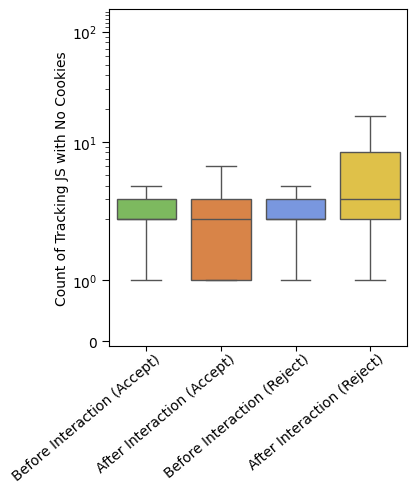

In [ ]:
from matplotlib.ticker import NullFormatter, FixedLocator
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib as mpl

# ─────────────────────────────────────────────────────────────
# Load data
# ─────────────────────────────────────────────────────────────
df_javascript_all = pd.read_csv('merged_js.csv')
df_cookie_all = pd.read_csv('merged_cookie.csv')


class_map = {
    1: class_1,
    2: class_2,
    3: class_3,
    4: class_4,
    5: class_5,
    6: class_6,
    7: class_7,
    8: class_8,
}

common_domains = set().union(*class_map.values())

modes = [
    "Before Interaction (Accept)",
    "After Interaction (Accept)",
    "Before Interaction (Reject)",
    "After Interaction (Reject)"
]

# ─────────────────────────────────────────────────────────────
# Helper
# ─────────────────────────────────────────────────────────────
def get_stage_counts(df):

    df = df[['visit_id', "clicked_stage", "domain"]]

    grouped = (
        df.groupby(['domain', 'clicked_stage'])
        .size()
        .reset_index(name='count')
    )

    result = pd.merge(
        df[['visit_id', 'domain', 'clicked_stage']],
        grouped,
        on=['domain', 'clicked_stage'],
        how='left'
    )

    result = result.drop_duplicates()

    result = result[
        ['visit_id', 'domain', 'clicked_stage', 'count']
    ]

    return result

json_data = download_disconnect_list()
# ─────────────────────────────────────────────────────────────

# Collect filtered data for all 4 stages
# ─────────────────────────────────────────────────────────────
final_data = []

for mode in modes:

    if json_data :
        df_javascript_all = apply_disconnect_categories_to_dataframe(df_javascript_all, domain_column='domain_script_url')
    print(f"\nProcessing: {mode}")

    # Stage-specific filtering
    df_js = df_javascript_all[
        df_javascript_all['clicked_stage'] == mode
    ].copy()

    df_cookie = df_cookie_all[
        df_cookie_all['clicked_stage'] == mode
    ].copy()

    # Remove first-party cookies
    df_cookie = df_cookie[
        df_cookie['domain_cookie'] != df_cookie['domain']
    ]

    # Domains with tracking cookies
    domains_with_tracking_cookies = set(df_cookie['domain'])

    # Domains WITHOUT tracking cookies
    domains_without_tracking_cookies = (
        common_domains - domains_with_tracking_cookies
    )

    # Keep invasive/general fingerprinting scripts
    df_js = df_js[
        (df_js['AllList'] == True) &
        (
            (df_js['FingerprintingInvasive'] == True) |
            (df_js['FingerprintingGeneral'] == True)
        ) &
        (df_js['domain_script_url'] != df_js['domain'])
    ]

    # Domains with fingerprinting scripts
    domains_with_fingerprinting_scripts = set(df_js['domain'])

    # Only FS and NO cookies
    domain_with_only_fs = (
        domains_with_fingerprinting_scripts &
        domains_without_tracking_cookies
    )

    # Keep only those rows
    df_js = df_js[
        df_js['domain'].isin(domain_with_only_fs)
    ]

    # Get counts
    counts = get_stage_counts(df_js)

    final_data.append(counts)

# Merge all stages together
final_df = pd.concat(final_data, ignore_index=True)
single_col_width = 3.5
# ─────────────────────────────────────────────────────────────
# Plot
# ─────────────────────────────────────────────────────────────
colors = ['#78C850', '#F08030', '#6890F0', '#F8D030']

f, axes = plt.subplots(
    1, 1,
    figsize=(
        single_col_width * 1.1,
        single_col_width * 1.25
    )
)

sns.boxplot(
    x='clicked_stage',
    y='count',
    order=modes,
    data=final_df,
    showfliers=False,
    ax=axes,
    palette=colors
)

# ── Symlog scale ─────────────────────────────────────────────
axes.set_yscale("symlog")
axes.set_ylim(-0.075, 160)

# ── Major ticks ──────────────────────────────────────────────
major_ticks = [0, 1, 10, 100]

axes.set_yticks(major_ticks)

axes.set_yticklabels(
    ['0', '$10^{0}$', '$10^{1}$', '$10^{2}$'],
    fontsize=10
)

# ── Minor dash marks ─────────────────────────────────────────
minor_ticks = [
    2, 3, 4, 5, 6, 7, 8, 9,
    20, 30, 40, 50, 60, 70, 80, 90,
    110, 120, 130, 140, 150
]

axes.yaxis.set_minor_locator(FixedLocator(minor_ticks))
axes.yaxis.set_minor_formatter(NullFormatter())

axes.tick_params(
    axis='y',
    which='major',
    length=5,
    width=0.8,
    left=True
)

axes.tick_params(
    axis='y',
    which='minor',
    length=3,
    width=0.5,
    left=True
)

# ── Labels ───────────────────────────────────────────────────
axes.set_ylabel(
    'Count of Tracking JS with No Cookies',
    labelpad=2
)

axes.set_xlabel('')

# ── X tick formatting ────────────────────────────────────────
xtl = axes.get_xticklabels()

axes.set_xticklabels(
    labels=xtl,
    rotation=40,
    ha="right",
    fontsize=10
)

dx = 12 / 72.
dy = 3 / 72.

offset = mpl.transforms.ScaledTranslation(
    dx,
    dy,
    f.dpi_scale_trans
)

for label in axes.xaxis.get_majorticklabels():
    label.set_transform(
        label.get_transform() + offset
    )
    label.set_fontsize(10)

plt.show()

f.savefig(
    'boxplot_tracking_js_no_cookies.pdf',
    bbox_inches='tight',
    dpi=300
)

In [6]:
def get_stage_counts(df):

    df = df[['visit_id', "clicked_stage", "domain"]]
    
    grouped = df.groupby(['domain', 'clicked_stage']).size().reset_index(name='count')
    print(grouped.head(10))
    # stages = ["Before Interaction", "After Interaction"]
    stages = df["clicked_stage"].unique().tolist()

    stages_df = pd.DataFrame({"clicked_stage": stages})
    print(stages_df)
    stages_df["key"] = 1
    print(stages_df)
    result = pd.merge(
        df[['visit_id', 'domain', 'clicked_stage']],
        grouped,
        on=['domain', 'clicked_stage'],
        how='left'
    )

    # Keep unique rows
    result = result.drop_duplicates()

    # Final column order
    result = result[['visit_id', 'domain', 'clicked_stage', 'count']]

    return result

In [ ]:
df1 = pd.read_csv("merged_cookie.csv")

In [ ]:
def boxplot_tracking_stages(df, FIG_NAME="stages_js"):
    data = get_stage_counts(df)

    # Print summary statistics
    print("\n===== Statistical Summary for Each Stage =====JS (main)\n")
    print(data.groupby("clicked_stage")["count"].describe())
    print("\n==============================================\n")

    custom_order = [
        "Before Interaction (Accept)",
        "After Interaction (Accept)",
        "Before Interaction (Reject)",
        "After Interaction (Reject)"
    ]

    colors = ['#78C850', '#F08030', '#6890F0', '#F8D030']

    # Create figure
    f, axes = plt.subplots(
        1, 1,
        figsize=(
            single_col_width * 0.95,
            single_col_width * 1.2
        )
    )
    # ── Axis border (spines) thickness ─────────────────────
    for spine in axes.spines.values():
        spine.set_linewidth(2)   # try 1.0–2.5 depending on how bold you want
    
    boxplot = sns.boxplot(
        x='clicked_stage',
        y='count',
        order=custom_order,
        data=data,
        showfliers=False,
        ax=axes,
        palette=colors
    )

    # ── Compute medians for each stage ──
    medians = []
    for i, stage in enumerate(custom_order):
        stage_data = data[data['clicked_stage'] == stage]['count']
        median_val = stage_data.median()
        medians.append(median_val)
        
        # Draw dashed horizontal line at median (only within the box area)
        # Get the x-position for this box (0, 1, 2, 3)
        x_pos = i
        # Draw dashed line spanning from left to right of the box
        axes.hlines(
            y=median_val,
            xmin=x_pos - 0.35,  # Adjust based on box width
            xmax=x_pos + 0.35,
            colors='gray',
            linestyle='--',
            linewidth=1.5,
            alpha=0.7,
            zorder=3
        )
        
        # Write median value inside box plot above the median line
        axes.text(
            x_pos,
            median_val,
            f'{median_val:.1f}',
            ha='center',
            va='bottom',
            fontsize=9,
            fontweight='bold',
            color='black',
            zorder=4
        )

    # Get highest value from plotted box elements
    max_range = max(
        line.get_ydata().max()
        for line in boxplot.get_lines()
        if line.get_ydata().size > 0
    )

    # Set symlog scale
    axes.set_yscale("symlog")
    
    # ── Y-axis label: make bold and bring it closer ──────────────────────────────
    axes.set_ylabel(
        f'Count of Tracking {FIG_NAME}',
        fontweight='bold',
        labelpad=2
    )

    # ── Y-axis ticks: 1, 10, 100 in 10^ format and bold ──────────────────
    major_ticks = [1, 10, 100]  # Remove 0 because symlog doesn't show 0 well
    axes.set_yticks(major_ticks)
    axes.set_yticklabels([r'$10^{%d}$' % int(np.log10(tick)) for tick in major_ticks])
    
    # Make y-tick labels bold
    for label in axes.get_yticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(10)

    # Minor ticks: fill in 2–9 between each decade
    from matplotlib.ticker import LogLocator, NullFormatter
    axes.yaxis.set_minor_locator(MinorSymLogLocator(1e-1))
    axes.yaxis.set_minor_formatter(NullFormatter())   # no labels on minors

    axes.tick_params(axis='y', which='major', length=5, width=0.8)
    axes.tick_params(axis='y', which='minor', length=3, width=0.5)

    # Add padding above maximum value
    ymax = np.ceil(max_range * 1.2)
    
    # Ensure ymax is at least 100 to show all ticks
    ymax = max(ymax, 100)

    # Apply limits
    axes.set_ylim(0.5, ymax)  # Start from 0.5 to show 10^0 properly

    # Labels
    plt.title('')
    axes.set_xlabel('')

    # X tick formatting - MAKE BOLD
    xtl = axes.get_xticklabels()
    axes.set_xticklabels(
        labels=custom_order,
        rotation=40,
        ha="right",
        fontsize=12,
        fontweight='bold'  # Make x labels bold
    )

    dx = 12 / 72.
    dy = 3 / 72.

    offset = mpl.transforms.ScaledTranslation(
        dx,
        dy,
        f.dpi_scale_trans
    )

    for label in axes.xaxis.get_majorticklabels():
        label.set_transform(
            label.get_transform() + offset
        )
        label.set_fontsize(10)
        label.set_fontweight('bold')  # Ensure bold

    plt.show()

    f.savefig(
        f'boxplot_js_{FIG_NAME}.pdf',
        bbox_inches='tight',
        dpi=300
    )

In [ ]:
# df1 = pd.read_csv("javascript_cookies_combined.csv")
df2 = pd.read_csv("merged_js.csv")

           domain                clicked_stage  count
0  000webhost.com   After Interaction (Accept)      4
1       01net.com   After Interaction (Accept)    414
2       01net.com   After Interaction (Reject)     10
3       01net.com  Before Interaction (Accept)      2
4       01net.com  Before Interaction (Reject)      2
5          021.rs   After Interaction (Accept)    208
6          021.rs   After Interaction (Reject)     30
7          021.rs  Before Interaction (Accept)      2
8          021.rs  Before Interaction (Reject)      2
9     0221.com.ar   After Interaction (Accept)    596
                 clicked_stage
0   After Interaction (Accept)
1  Before Interaction (Accept)
2  Before Interaction (Reject)
3   After Interaction (Reject)
                 clicked_stage  key
0   After Interaction (Accept)    1
1  Before Interaction (Accept)    1
2  Before Interaction (Reject)    1
3   After Interaction (Reject)    1

===== Statistical Summary for Each Stage =====JS (main)

             

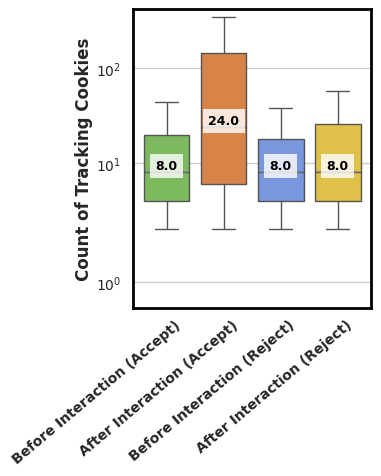

In [48]:
boxplot_tracking_stages(df1, FIG_NAME="Cookies")

           domain                clicked_stage  count
0  000webhost.com   After Interaction (Accept)     14
1  000webhost.com   After Interaction (Reject)     12
2  000webhost.com  Before Interaction (Accept)     17
3  000webhost.com  Before Interaction (Reject)     16
4       01net.com   After Interaction (Accept)    101
5       01net.com   After Interaction (Reject)     35
6       01net.com  Before Interaction (Accept)     15
7       01net.com  Before Interaction (Reject)     15
8          021.rs   After Interaction (Accept)     88
9          021.rs   After Interaction (Reject)     49
                 clicked_stage
0  Before Interaction (Accept)
1   After Interaction (Accept)
2  Before Interaction (Reject)
3   After Interaction (Reject)
                 clicked_stage  key
0  Before Interaction (Accept)    1
1   After Interaction (Accept)    1
2  Before Interaction (Reject)    1
3   After Interaction (Reject)    1

===== Statistical Summary for Each Stage =====JS (main)

             

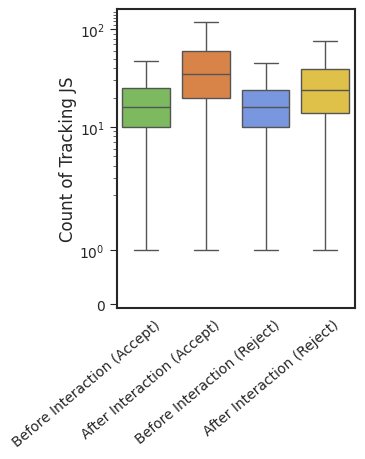

In [63]:
boxplot_tracking_stages(df2, FIG_NAME="JS")